# L22 worked example: reading a project's history from git

Every commit records a date, an author and a message, and many carry trailer lines such as
`Co-Authored-By:` at the end of the message. Read back with `git log`, the history of a
repository becomes data you can plot. This notebook asks four questions of one repository:

1. **When did the work happen?** Commits per week.
2. **Who or what wrote it?** The co-author trailers on those commits.
3. **How did it arrive?** The pull requests merged into the main branch.
4. **How did one file grow?** The length of a file, such as `README.md` or `CLAUDE.md`, at every
   commit that changed it.

In class it reads this course's repository. Then point it at your own final-project repository,
and ask of your project what the lecture asked of the course: when did the work happen, where
did it change direction, and which of your fixes should have become a rule written down.

## Run this first on Colab

Colab starts from its own preinstalled environment rather than this course's `uv`
environment, so run the cell below before anything else. It installs what this
notebook needs and Colab does not already have. Outside Colab it does nothing, so
you can run it or skip it.


In [ ]:
# Run this first on Colab. Anywhere else this cell does nothing.
#
# Only genuinely missing packages are installed, so Colab's own versions of
# everything it already ships are left alone.
import importlib.util
import subprocess
import sys

REQUIREMENTS = {
    "matplotlib": "matplotlib",
}


def _missing(module):
    try:
        return importlib.util.find_spec(module) is None
    except ModuleNotFoundError:  # the parent package is absent
        return True


if "google.colab" in sys.modules:
    need = sorted({pip for mod, pip in REQUIREMENTS.items() if _missing(mod)})
    if need:
        print("installing:", " ".join(need))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
    print("Colab setup done." if need else "Colab: nothing to install.")


## Choose the repository

Set `REPO` to a local checkout, or set `REPO_URL` to a repository to clone (on Colab there is no
local checkout, so cloning is the way in; a private repository needs a token in the URL, which
you should not save in the notebook). `FILE` is the file whose growth to plot, and `CUTOFF`
freezes the history at a date so that the numbers do not move as commits land.

In [2]:
REPO = "../.."          # this course's repository, when the notebook runs from lectures/l22
REPO_URL = ""           # e.g. "https://github.com/you/your-project.git" to clone instead
FILE = "CLAUDE.md"      # try "README.md" on your own project
CUTOFF = "2026-11-04T23:59:59"   # "" for everything up to now

In [3]:
import collections, datetime as dt, re, subprocess, tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

if REPO_URL:
    REPO = tempfile.mkdtemp(prefix="repo-")
    subprocess.run(["git", "clone", "--quiet", REPO_URL, REPO], check=True)


def git(*args):
    return subprocess.run(["git", *args], cwd=REPO, capture_output=True, text=True, check=True).stdout


until = [f"--until={CUTOFF}"] if CUTOFF else []
print(git("log", "-1", "--format=%h %ad %s", "--date=short", *until).strip())

b43ba5f 2026-11-04 Merge pull request #206 from jkitchin/optional-page-and-map


## 1. When did the work happen?

`--no-merges` drops the merge commits that pull requests create, so each commit counted is a
change somebody made. `%x1f` and `%x1e` are unit and record separators, characters that do not
appear in commit messages, so a message containing a comma or a newline cannot break the parse.

In [4]:
raw = git("log", "--no-merges", *until, "--format=%h%x1f%ad%x1f%an%x1f%B%x1e", "--date=short")
commits = []
for rec in raw.split("\x1e"):
    rec = rec.strip()
    if not rec:
        continue
    h, day, author, body = rec.split("\x1f", 3)
    co = re.findall(r"Co-Authored-By:\s*([^<\n]+)", body, re.I)
    commits.append({"hash": h, "day": dt.date.fromisoformat(day), "author": author,
                    "coauthor": re.sub(r"\s*\(.*?\)", "", co[0]).strip() if co else "none"})

days = [c["day"] for c in commits]
print(f"{len(commits)} commits from {min(days)} to {max(days)}")
for author, k in collections.Counter(c["author"] for c in commits).most_common():
    print(f"  {k:5d}  {author}")

354 commits from 2026-07-20 to 2026-11-04
    196  John Kitchin
    144  Victor Alves
     13  Claude
      1  github-actions[bot]


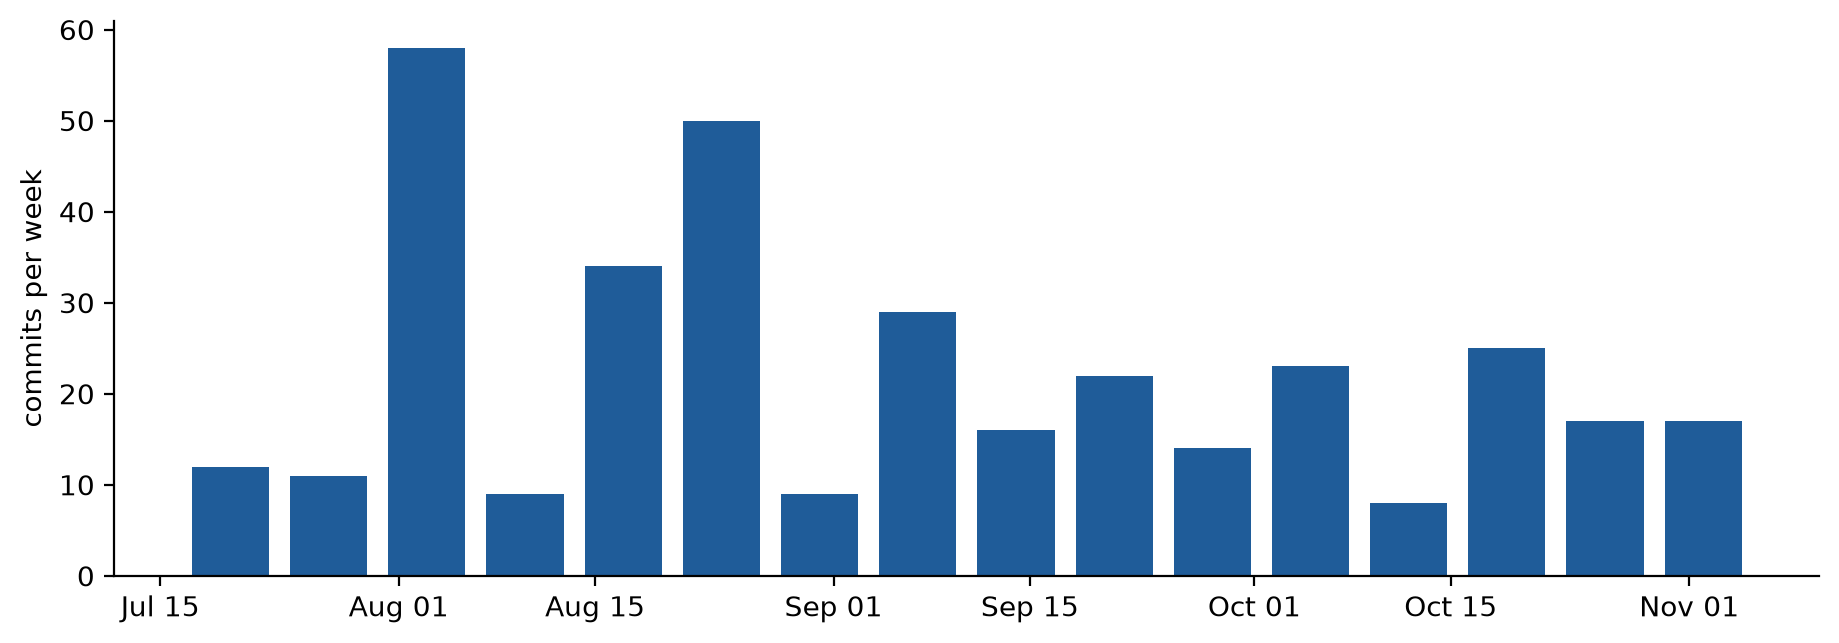

busiest week: 2026-08-03 with 58 commits


In [5]:
def monday(d):
    return d - dt.timedelta(days=d.weekday())

weeks = collections.Counter(monday(d) for d in days)
first, last = min(weeks), max(weeks)
xs = [first + dt.timedelta(weeks=i) for i in range((last - first).days // 7 + 1)]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(xs, [weeks[w] for w in xs], width=5.5, color="#1f5c99")
ax.set_ylabel("commits per week")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.spines[["top", "right"]].set_visible(False)
plt.show()
busiest = max(xs, key=lambda w: weeks[w])
print(f"busiest week: {busiest} with {weeks[busiest]} commits")

## 2. Who or what wrote it?

The `Co-Authored-By:` trailer is how Git records a second author, and AI coding assistants
add one naming the model. A trailer is only as honest as the person who left it in: a commit
with no trailer may still have had help, so read this as what the project declared.

    140   39.5%  Claude Opus 5
    111   31.4%  Claude Opus 5.5
     49   13.8%  none
     47   13.3%  Claude Opus 4.8
      5    1.4%  Claude Sonnet 5
      2    0.6%  Claude


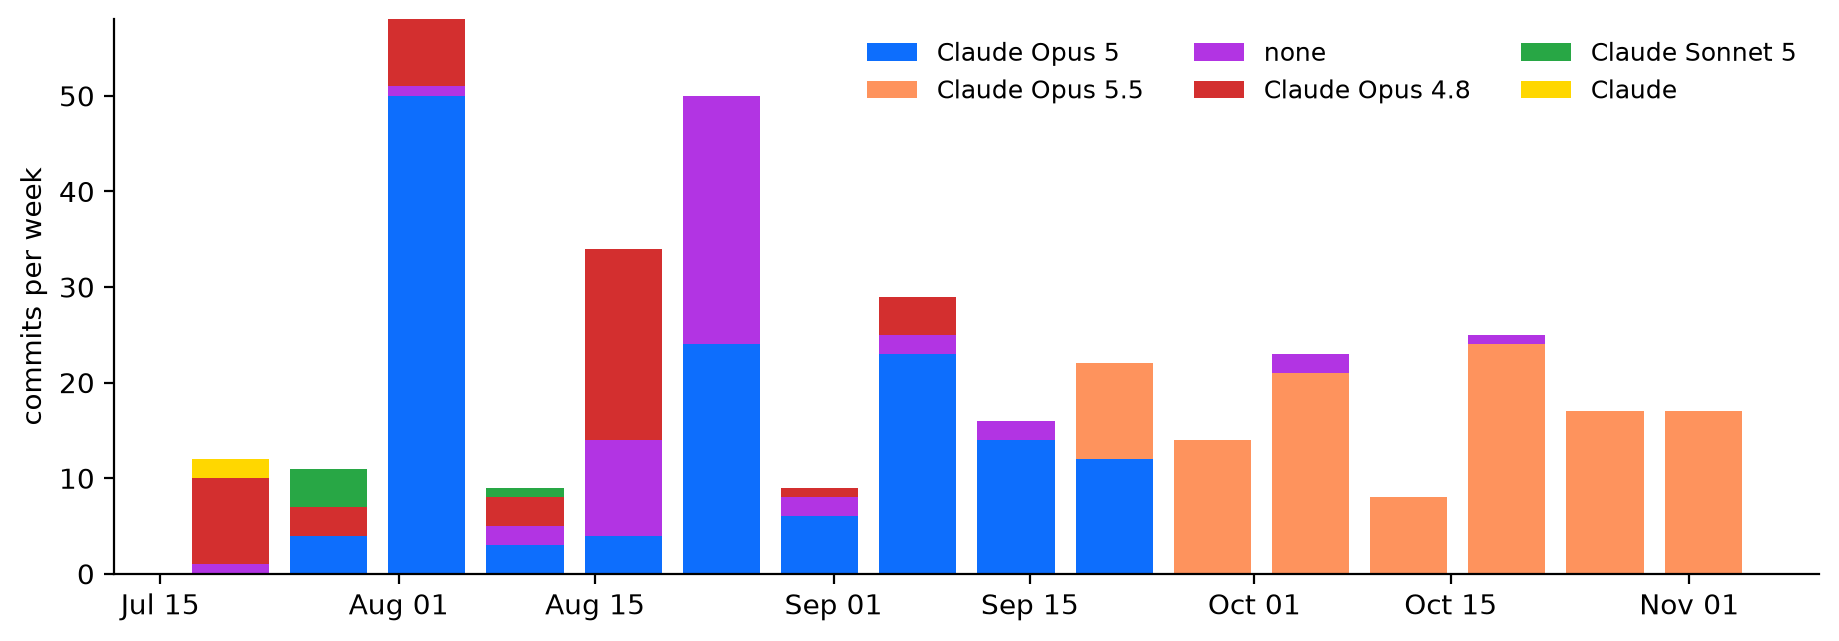

In [6]:
by = collections.Counter(c["coauthor"] for c in commits)
for name, k in by.most_common():
    print(f"  {k:5d}  {100 * k / len(commits):5.1f}%  {name}")

names = [n for n, _ in by.most_common()]
fig, ax = plt.subplots(figsize=(11, 3.6))
bottom = [0] * len(xs)
for name in names:
    per = collections.Counter(monday(c["day"]) for c in commits if c["coauthor"] == name)
    h = [per[w] for w in xs]
    ax.bar(xs, h, width=5.5, bottom=bottom, label=name)
    bottom = [b + v for b, v in zip(bottom, h)]
ax.set_ylabel("commits per week")
ax.legend(frameon=False, fontsize=9, ncol=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. How did it arrive?

On GitHub a merged pull request leaves a merge commit on the main branch whose message starts
"Merge pull request #". `--first-parent` follows the main branch only, so commits inside each
pull request are not double counted. A project that pushes straight to main will show none,
which is itself worth knowing.

In [7]:
merges = git("log", "--first-parent", "--merges", *until, "--format=%ad %s", "--date=short").splitlines()
prs = [m for m in merges if "Merge pull request #" in m]
print(f"{len(prs)} pull requests merged into the main line")
print("the five most recent:")
for line in prs[:5]:
    print("  ", line[:100])

133 pull requests merged into the main line
the five most recent:
   2026-11-04 Merge pull request #206 from jkitchin/optional-page-and-map
   2026-11-04 Merge pull request #214 from jkitchin/l19-agents
   2026-11-02 Merge pull request #211 from jkitchin/l18-slide26-ask-keys
   2026-11-01 Merge pull request #209 from jkitchin/hold-a08
   2026-11-01 Merge pull request #208 from jkitchin/release-l18


## 4. How did one file grow?

`git log -- FILE` lists the commits that changed the file, and `git show HASH:FILE` prints the
file as it was at that commit. For a conventions file, the steps in this plot are the rules
being written; the commit messages say which mistake each one came from.

CLAUDE.md: 42 revisions, 241 lines on 2026-07-20, 984 on 2026-11-04


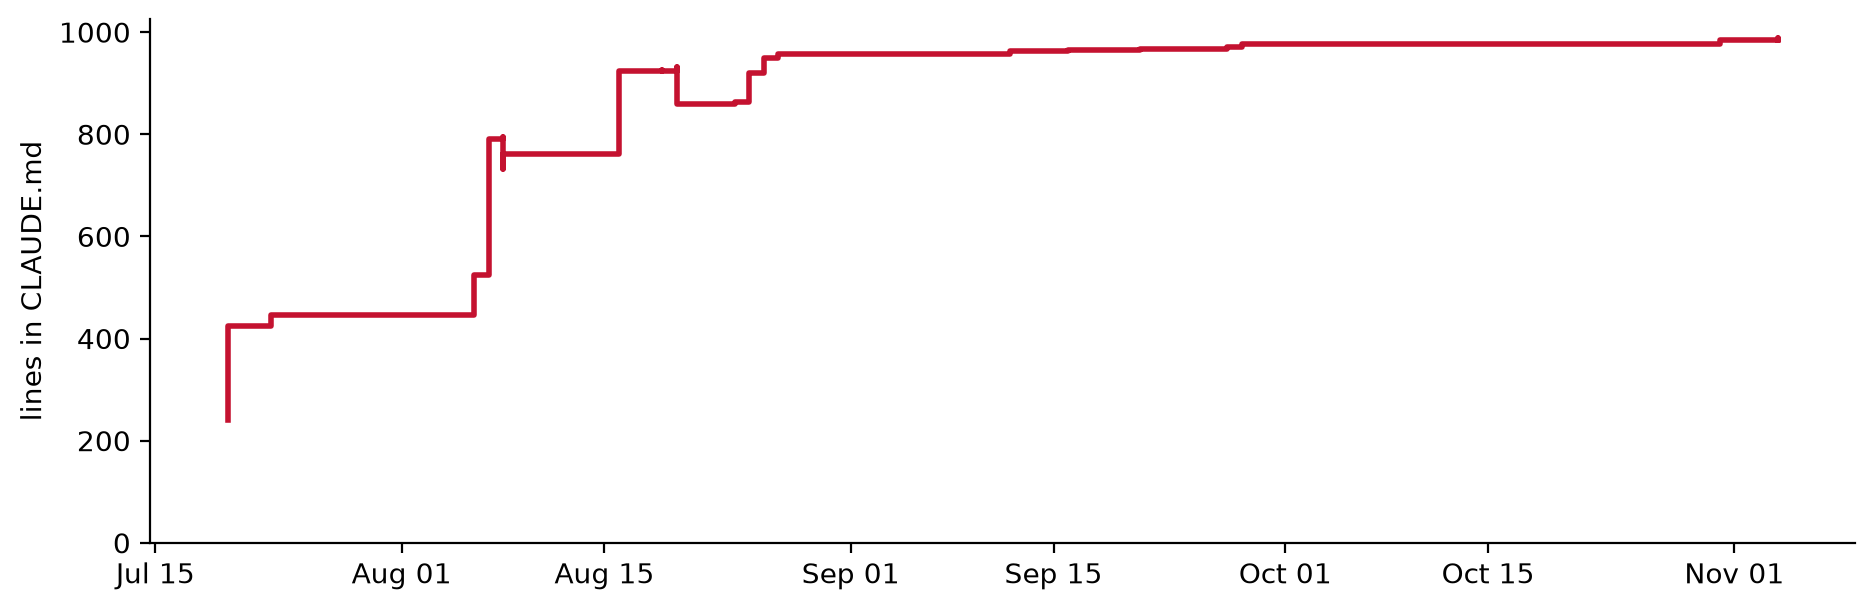

In [8]:
hist = []
for line in git("log", "--reverse", *until, "--format=%h %ad", "--date=short", "--", FILE).splitlines():
    h, day = line.split()
    try:
        text = git("show", f"{h}:{FILE}")
    except subprocess.CalledProcessError:   # the commit deleted or renamed the file
        continue
    hist.append((dt.date.fromisoformat(day), text.count("\n"), h))

if not hist:
    print(f"{FILE} has no history in this repository; set FILE to a file that exists")
else:
    print(f"{FILE}: {len(hist)} revisions, {hist[0][1]} lines on {hist[0][0]}, {hist[-1][1]} on {hist[-1][0]}")
    fig, ax = plt.subplots(figsize=(11, 3.4))
    ax.step([d for d, _, _ in hist], [n for _, n, _ in hist], where="post", color="#c41230", lw=2)
    ax.set_ylabel(f"lines in {FILE}")
    ax.set_ylim(0, None)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

In [9]:
# The five commits that added the most lines to FILE, and what their messages say.
jumps = sorted(((b[1] - a[1], b[2]) for a, b in zip(hist, hist[1:])), reverse=True)[:5]
for added, h in jumps:
    print(f"+{added:4d}  {git('log', '-1', '--format=%ad %s', '--date=short', h).strip()[:100]}")

+ 156  2026-08-07 Build a general index, and require entries in every lecture
+  85  2026-08-16 Merge remote-tracking branch 'origin/main' into map-game
+  72  2026-07-20 L1: survey the stack, generated figures, deck sized for 110 minutes (#30)
+  56  2026-08-07 CLAUDE.md: ban the anaphoric evaluative coda, add topic-titled slides
+  53  2026-08-16 Score the modules, and make a retake cost more than answering


## Try it

- Point `REPO` (or `REPO_URL`) at your final-project repository. Which week did most of the work
  happen in, and does that match your memory of the project?
- Set `FILE` to your `README.md`. When did it last change, and does it still describe the project
  you built?
- Read the messages of your ten most recent commits. Could a teammate tell from them why each
  change was made? Rewrite one that could not.
- Find one bug you fixed twice. Write the rule that would have stopped the second one in a file at
  the root of your project, and commit it with a message saying where it came from.